<a href="https://colab.research.google.com/github/y-adulyasak/SCOA_PhD/blob/main/S10_P2P/two_stage_P2P_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two-stage stock positioning: deterministic vs SAA vs kNN

**PhD Seminar (From Predictive to Prescriptive Analytics).**

**Yossiri Adulyasak**

A plant sends its stock to several distribution centres (DCs) **before** the season's demand is known
(stage 1). Once demand is seen, a truck can move units between DCs (stage 2). Before the season we also
see a signal $x$ that hints at where demand will surge.

Every approach below solves the **same** two-stage linear program. Only the scenarios and their weights
change:

| approach | scenarios fed to the LP | weight of each |
|---|---|---|
| **Deterministic** | 1: the average past season | 1 |
| **SAA** | all $N$ past seasons | $1/N$ |
| **kNN** | the $k$ past seasons whose signal is closest to today's $x$ | $1/k$ |

We use two instances, solved by the **same functions**:

* **Instance 1**: 2 DCs, 30 past seasons. Exactly the workbook's data (Sheet 7), so the plans match Sheets 8–12.
* **Instance 2**: 4 DCs, 100 past seasons. A bigger network with more scenarios.

Then we **simulate**: draw new seasons from the true process, keep each approach's stage-1 plan fixed,
let the truck react optimally in each season, and average the cost.

In [1]:
!pip install -q "pyomo>=6.9" highspy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyomo.environ as pyo

SOLVER = pyo.SolverFactory("highs")        # HiGHS: open-source LP solver, installed by highspy
assert SOLVER.available(), "HiGHS not found: run  !pip install -U pyomo highspy  and restart the runtime"
print("Pyomo with HiGHS: ready")

Pyomo with HiGHS: ready


---
# Part 1: One model for any number of DCs

**Data.** DCs $j \in J$; scenarios $s$ with weight $w_s$ and demand $d_{s,j}$; total stock $Q$; truck
capacity $T$; cost $c_{ij}$ to move a unit from DC $i$ to DC $j$; lost-sale cost $\ell_j$; leftover
cost $h$.

**Decisions.**

| variable | stage | meaning |
|---|---|---|
| $z_j$ | 1 | units placed at DC $j$ before the season (the same in every scenario) |
| $t_{s,ij}$ | 2 | units the truck moves from DC $i$ to DC $j$ in scenario $s$ |
| $u_{s,j}$ | 2 | demand lost at DC $j$ in scenario $s$ |
| $o_{s,j}$ | 2 | units left over at DC $j$ in scenario $s$ |

**The LP** (the extensive form of the two-stage problem):

$$
\begin{aligned}
\min\quad & \sum_s w_s \Bigl[\ \sum_{i \ne j} c_{ij}\, t_{s,ij} \;+\; \sum_j \bigl(\ell_j\, u_{s,j} + h\, o_{s,j}\bigr) \Bigr]
  && \text{expected cost}\\
\text{s.t.}\quad & \textstyle\sum_j z_j = Q && \text{place all the stock}\\
& z_j + \textstyle\sum_{i \ne j} t_{s,ij} - \sum_{k \ne j} t_{s,jk} + u_{s,j} - o_{s,j} = d_{s,j}
  && \text{every } s, j \quad\text{(stock in − out + lost − left = demand)}\\
& \textstyle\sum_{i \ne j} t_{s,ij} \le T && \text{every } s \quad\text{(one truck)}\\
& z,\ t,\ u,\ o \ \ge 0
\end{aligned}
$$

The function below builds and solves the model.

In [2]:
from numpy._core.numeric import False_
def two_stage_lp(inst, D, w, z_fixed=None, print_model = False):
    '''Solve the two-stage LP.
         inst    : the instance (DCs, costs, truck, ...)
         D       : demand per scenario, an array with one row per scenario and one column per DC
         w       : scenario weights (they sum to 1)
         z_fixed : optional stage-1 stock per DC; if given, only stage 2 is optimized
       Returns the stage-1 stock z, the expected cost, and the cost of each scenario.'''
    DCS = range(len(inst["dc"]))
    SCEN = range(len(w))
    LANES = [(i, j) for i in DCS for j in DCS if i != j]            # truck can go from i to j

    m = pyo.ConcreteModel()
    m.z    = pyo.Var(DCS, within=pyo.NonNegativeReals)              # stage 1: stock placed at each DC
    m.ship = pyo.Var(SCEN, LANES, within=pyo.NonNegativeReals)      # stage 2: units moved i -> j
    m.lost = pyo.Var(SCEN, DCS, within=pyo.NonNegativeReals)        # stage 2: demand not served
    m.left = pyo.Var(SCEN, DCS, within=pyo.NonNegativeReals)        # stage 2: stock left over

    m.place_all = pyo.Constraint(expr=sum(m.z[j] for j in DCS) == inst["Q"])

    def balance(m, s, j):
        arrive = sum(m.ship[s, i, j] for i in DCS if i != j)
        leave  = sum(m.ship[s, j, k] for k in DCS if k != j)
        return m.z[j] + arrive - leave + m.lost[s, j] - m.left[s, j] == D[s][j]
    m.balance = pyo.Constraint(SCEN, DCS, rule=balance)

    def truck(m, s):
        return sum(m.ship[s, i, j] for (i, j) in LANES) <= inst["truck"]
    m.truck = pyo.Constraint(SCEN, rule=truck)

    def scenario_cost(m, s):
        moving  = sum(inst["ship_cost"][i][j] * m.ship[s, i, j] for (i, j) in LANES)
        lost    = sum(inst["lost_cost"][j] * m.lost[s, j] for j in DCS)
        leftover = sum(inst["left_cost"] * m.left[s, j] for j in DCS)
        return moving + lost + leftover
    m.scenario_cost = pyo.Expression(SCEN, rule=scenario_cost)
    m.expected_cost = pyo.Objective(expr=sum(w[s] * m.scenario_cost[s] for s in SCEN), sense=pyo.minimize)

    if z_fixed is not None:                                         # simulation mode: stage 1 is given
        for j in DCS:
            m.z[j].fix(z_fixed[j])
        m.place_all.deactivate()

    if print_model: m.pprint()

    result = SOLVER.solve(m)
    assert pyo.check_optimal_termination(result), result.solver.termination_condition
    return {"z": np.array([m.z[j].value for j in DCS]),
            "cost": pyo.value(m.expected_cost),
            "scenario_cost": np.array([pyo.value(m.scenario_cost[s]) for s in SCEN])}

---
# Part 2: The two instances

An instance is a dictionary with three groups of entries:

1. **The network**: DCs, total stock, truck capacity and costs.
2. **The true process**, which we use **only** to draw new seasons for the simulation (and to create
   Instance 2's history). The season type depends on the signal through
   $P(\text{type } m \mid x) \propto e^{\beta_m x}$. Given the type, demand at each DC is
   Normal(mean, sd), rounded and at least 0. None of the approaches sees this true demand function: they only see the
   past seasons.
3. **The past seasons**: signal `x`, season `type` and `demand` (one row per season, one column per DC).

Instance 1 has two types with $\beta = (1, -1)$, so $P(\text{A-surge} \mid x) = 1/(1+e^{-2x})$, the
same rule as in the workbook.

In [3]:
INSTANCE_1 = {
    "name": "Instance 1: 2 DCs, 30 past seasons",
    # 1. the network
    "dc": ["A", "B"],
    "Q": 100,                                  # units placed before the season
    "truck": 15,                               # most units the truck can move after demand is seen
    "ship_cost": [[0, 3],                      # $ per unit moved from the row DC to the column DC
                  [3, 0]],
    "lost_cost": [16, 6],                      # $ per unit of lost demand at each DC
    "left_cost": 1,                            # $ per unit left over at any DC
    # 2. the true process (only used to draw NEW seasons)
    "types": ["A-surge", "B-surge"],
    "beta": [1, -1],                           # P(type | x) is proportional to exp(beta * x)
    "mean": [[80, 30],                         # mean demand at (A, B) in an A-surge season
             [25, 75]],                        # mean demand at (A, B) in a B-surge season
    "sd": 6,                                   # demand noise (standard deviation) at every DC
}
# 3. the past seasons: Sheet 7 of TwoStage_examples.xlsx (seasons 1-20 are Sheet 6's)
INSTANCE_1["x"] = np.array([1.3, 0.8, 1.0, -1.1, 0.9, -0.2, -0.2, 1.1, -0.4, -1.3, -0.5, -1.2, -1.8, -0.1, 0.4,
                            -2.2, 0.0, 0.3, 0.2, -1.3, -0.4, -1.1, 0.7, -1.1, 2.0, 0.9, -0.4, 0.6, 1.6, 2.8])
INSTANCE_1["type"] = np.array([0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1,     # 0 = A-surge, 1 = B-surge
                               1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0])
INSTANCE_1["demand"] = np.array([
    [80, 30], [20, 76], [81, 30], [25, 79], [76, 34], [24, 75], [79, 35], [85, 30], [22, 86], [83, 23],
    [25, 74], [29, 74], [21, 83], [68, 22], [22, 72], [24, 75], [86, 21], [98, 34], [75, 27], [22, 62],
    [27, 68], [22, 68], [21, 75], [17, 84], [72, 27], [80, 34], [26, 75], [83, 32], [74, 33], [76, 23]])

Assuming two scenarios: (80, 30) and
(25, 75), each with weight 1/2, the LP should place **65 units at A** at an expected cost of **\$162.50** (see slides).

In [4]:
check = two_stage_lp(INSTANCE_1, D=np.array([[80, 30], [25, 75]]), w=[0.5, 0.5], print_model = True)
print("stock at A, B:", check["z"], "  expected cost:", round(check["cost"], 2))

4 Var Declarations
    left : Size=4, Index={0, 1}*{0, 1}
        Key    : Lower : Value : Upper : Fixed : Stale : Domain
        (0, 0) :     0 :  None :  None : False :  True : NonNegativeReals
        (0, 1) :     0 :  None :  None : False :  True : NonNegativeReals
        (1, 0) :     0 :  None :  None : False :  True : NonNegativeReals
        (1, 1) :     0 :  None :  None : False :  True : NonNegativeReals
    lost : Size=4, Index={0, 1}*{0, 1}
        Key    : Lower : Value : Upper : Fixed : Stale : Domain
        (0, 0) :     0 :  None :  None : False :  True : NonNegativeReals
        (0, 1) :     0 :  None :  None : False :  True : NonNegativeReals
        (1, 0) :     0 :  None :  None : False :  True : NonNegativeReals
        (1, 1) :     0 :  None :  None : False :  True : NonNegativeReals
    ship : Size=4, Index={0, 1}*{(0, 1), (1, 0)}
        Key       : Lower : Value : Upper : Fixed : Stale : Domain
        (0, 0, 1) :     0 :  None :  None : False :  True : NonNega

**The true demand process.** `draw_seasons` draws new seasons at a given signal.

In [5]:
def p_type(inst, x):
    '''True probability of each season type given the signal x.'''
    score = np.exp(np.array(inst["beta"]) * x)
    return score / score.sum()


def draw_seasons(inst, x, n, rng):
    '''Draw n new seasons at signal x: first the season type, then demand = round(mean + sd * noise), at least 0.'''
    types = rng.choice(len(inst["types"]), size=n, p=p_type(inst, x))
    mean = np.array(inst["mean"])[types]                       # one row of means per season
    noise = rng.standard_normal((n, len(inst["dc"])))
    demand = np.maximum(0, np.round(mean + inst["sd"] * noise))
    return types, demand


print("Instance 1, P(type | x = 0.9):", {t: round(float(p), 2) for t, p in zip(INSTANCE_1["types"], p_type(INSTANCE_1, 0.9))})

Instance 1, P(type | x = 0.9): {'A-surge': 0.86, 'B-surge': 0.14}


**Instance 2** adds two DCs. They sit on a line A–B–C–D, so moving a unit costs \$2 per hop, and a lost
sale is highest at A. Each season one DC surges (mean 88; the others 38). A positive signal favours A, and a negative one towards D. The 100 past seasons are drawn from this process with $x \sim N(0, 1)$.

In [6]:
INSTANCE_2 = {
    "name": "Instance 2: 4 DCs, 100 past seasons",
    # 1. the network
    "dc": ["A", "B", "C", "D"],
    "Q": 200,
    "truck": 30,
    "ship_cost": [[0, 2, 4, 6],                # DCs on a line A-B-C-D: $2 per hop
                  [2, 0, 2, 4],
                  [4, 2, 0, 2],
                  [6, 4, 2, 0]],
    "lost_cost": [16, 12, 9, 6],
    "left_cost": 1,
    # 2. the true process
    "types": ["A-surge", "B-surge", "C-surge", "D-surge"],
    "beta": [2, 0.7, -0.7, -2],                # x > 0 favours A (and B), x < 0 favours D (and C)
    "mean": [[88, 38, 38, 38],
             [38, 88, 38, 38],
             [38, 38, 88, 38],
             [38, 38, 38, 88]],
    "sd": 6,
}


def add_history(inst, n, seed):
    '''Create n past seasons: signal x ~ N(0, 1) rounded to 0.1, then one season drawn at that x.'''
    rng = np.random.default_rng(seed)
    x = np.round(rng.standard_normal(n), 1)
    seasons = [draw_seasons(inst, xi, 1, rng) for xi in x]
    inst["x"] = x
    inst["type"] = np.array([types[0] for types, demand in seasons])
    inst["demand"] = np.array([demand[0] for types, demand in seasons])


add_history(INSTANCE_2, n=100, seed=5)

for inst in (INSTANCE_1, INSTANCE_2):
    counts = np.bincount(inst["type"], minlength=len(inst["types"]))
    print(f"{inst['name']}:  {dict(zip(inst['types'], counts.tolist()))}")

Instance 1: 2 DCs, 30 past seasons:  {'A-surge': 15, 'B-surge': 15}
Instance 2: 4 DCs, 100 past seasons:  {'A-surge': 31, 'B-surge': 19, 'C-surge': 12, 'D-surge': 38}


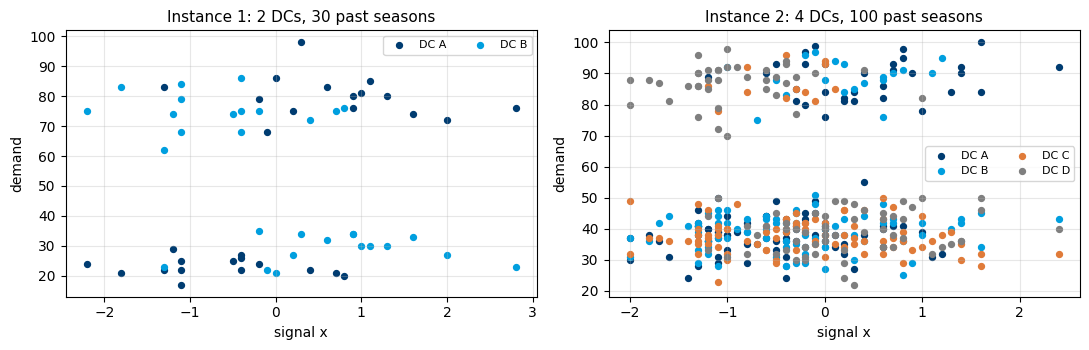

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colors = ["#003C71", "#009FDF", "#E07B39", "#7F7F7F"]
for ax, inst in zip(axes, (INSTANCE_1, INSTANCE_2)):
    for j, dc in enumerate(inst["dc"]):
        ax.scatter(inst["x"], inst["demand"][:, j], s=18, color=colors[j], label=f"DC {dc}")
    ax.set_title(inst["name"], fontsize=11); ax.set_xlabel("signal x"); ax.set_ylabel("demand")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

---
# Part 3: Scenario-based LP models

`scenarios` returns the demand rows and their weights. That is the **only** place where the approaches
differ. kNN ranks past seasons by $|x_i - x_0|$; ties go to the earlier season, as in the workbook.

In [8]:
APPROACHES = {                  # name: (method, k)
    "Deterministic": ("mean", None),
    "SAA":           ("all",  None),
    "kNN, k=3":      ("knn",  3),
    "kNN, k=5":      ("knn",  5),
    "kNN, k=10":     ("knn", 10),
}


def scenarios(inst, method, x0, k=None):
    '''Scenarios (demand rows), their weights, and which past seasons they come from.'''
    D, n = inst["demand"], len(inst["demand"])
    if method == "mean":                                   # one scenario: the average season
        return D.mean(axis=0, keepdims=True), np.array([1.0]), None
    if method == "all":                                    # every past season, equal weight
        return D, np.full(n, 1 / n), np.arange(n)
    if method == "knn":                                    # the k seasons with the closest signal
        distance = np.round(np.abs(inst["x"] - x0), 6)
        nearest = np.argsort(distance, kind="stable")[:k]  # stable sort: ties go to the earlier season
        return D[nearest], np.full(k, 1 / k), nearest


# example: the 5 seasons kNN uses for Instance 1 at x0 = 0.9
D, w, used = scenarios(INSTANCE_1, "knn", 0.9, k=5)
pd.DataFrame({"season": used + 1, "signal x": INSTANCE_1["x"][used],
              "type": np.array(INSTANCE_1["types"])[INSTANCE_1["type"][used]],
              "demand A": D[:, 0], "demand B": D[:, 1], "weight": w})

,season,signal x,type,demand A,demand B,weight
0,5,0.9,A-surge,76,34,0.2
1,26,0.9,A-surge,80,34,0.2
2,2,0.8,B-surge,20,76,0.2
3,3,1.0,A-surge,81,30,0.2
4,8,1.1,A-surge,85,30,0.2


---
# Part 4: Solve and simulate, Instance 1

`compare` does two things for every approach:

1. **Plan.** Solve the LP with the approach's scenarios. This gives the stock per DC, and the cost
   the LP *expects* (its in-sample cost).
2. **Simulate.** Draw 1,000 new seasons at today's signal from the true process. All approaches face the
   **same** 1,000 seasons, so differences are not luck of the draw. Keep the plan fixed, let the truck react
   optimally in each season (the same LP with `z_fixed`), and average the cost. The ± column is a 95%
   confidence half-width.

As a yardstick, the last row plans with 2,000 draws from the true distribution at $x_0$: this represents the
best any approach could do (if the true demand function is known).

**Perfect foresight** (last row) knows each new season's demand *before* placing the stock: the same LP,
solved once per season with that season as its only scenario. No approach can reach it. It is not zero here
(unlike the newsvendor) because the total stock $Q$ is fixed: when total demand exceeds $Q$, some sales are
lost even with perfect placement.

**Coefficient of prescriptiveness** (Bertsimas & Kallus, 2020), computed on the simulated costs:

$$P = 1 - \frac{\text{cost} - \text{cost}_{\text{perfect foresight}}}{\text{cost}_{\text{SAA}} - \text{cost}_{\text{perfect foresight}}}$$

$P = 0$: no better than SAA. $P = 1$: as good as knowing the future. $P < 0$: worse than SAA.

In [9]:
def compare(inst, x0, n_test=1000, seed=1):
    rng = np.random.default_rng(seed)
    _, test = draw_seasons(inst, x0, n_test, rng)              # the new seasons, shared by all approaches
    equal = np.full(n_test, 1 / n_test)

    rows, beliefs = [], []
    for name, (method, k) in APPROACHES.items():
        D, w, used = scenarios(inst, method, x0, k)
        plan = two_stage_lp(inst, D, w)                                   # 1. plan
        sim = two_stage_lp(inst, test, equal, z_fixed=plan["z"])          # 2. simulate
        rows.append({"approach": name, "scenarios": len(w),
                     **{f"stock {dc}": z for dc, z in zip(inst["dc"], plan["z"])},
                     "LP expects": plan["cost"],
                     "simulated cost": sim["cost"],
                     "±": 1.96 * sim["scenario_cost"].std() / np.sqrt(n_test)})
        if used is not None:                                              # share of each season type
            beliefs.append({"approach": name, **{t: np.mean(inst["type"][used] == m)
                                                 for m, t in enumerate(inst["types"])}})

    # yardstick: plan with 2,000 draws from the TRUE distribution at x0
    _, D_true = draw_seasons(inst, x0, 2000, np.random.default_rng(seed + 100))
    plan = two_stage_lp(inst, D_true, np.full(2000, 1 / 2000))
    sim = two_stage_lp(inst, test, equal, z_fixed=plan["z"])
    rows.append({"approach": "yardstick: true distribution", "scenarios": 2000,
                 **{f"stock {dc}": z for dc, z in zip(inst["dc"], plan["z"])},
                 "LP expects": plan["cost"], "simulated cost": sim["cost"],
                 "±": 1.96 * sim["scenario_cost"].std() / np.sqrt(n_test)})
    beliefs.append({"approach": "true P(type | x0)", **dict(zip(inst["types"], p_type(inst, x0)))})

    # perfect foresight: knows each new season's demand BEFORE placing stock
    # (the same LP, solved once per season with that season as its only scenario)
    pf = np.array([two_stage_lp(inst, test[s:s + 1], [1.0])["cost"] for s in range(n_test)])
    rows.append({"approach": "perfect foresight", "scenarios": 1,
                 "simulated cost": pf.mean(), "±": 1.96 * pf.std() / np.sqrt(n_test)})

    table = pd.DataFrame(rows).set_index("approach")
    best = table.loc[list(APPROACHES), "simulated cost"].min()
    table["vs best approach"] = (table["simulated cost"] / best - 1).map("{:+.0%}".format)

    # coefficient of prescriptiveness: 0 = SAA, 1 = perfect foresight
    cost_saa = table.loc["SAA", "simulated cost"]
    cost_pf = table.loc["perfect foresight", "simulated cost"]
    P = 1 - (table["simulated cost"] - cost_pf) / (cost_saa - cost_pf)
    table = table.round(1)
    table["P"] = P.round(2)
    return table.fillna(""), pd.DataFrame(beliefs).set_index("approach").round(2)


X0 = 0.9                                                       # today's signal
result_1, beliefs_1 = compare(INSTANCE_1, X0)
result_1

,scenarios,stock A,stock B,LP expects,simulated cost,±,vs best approach,P
approach,,,,,,,,
Deterministic,1,51.4,48.6,20.8,255.5,6.4,+123%,-1.22
SAA,30,64.0,36.0,170.5,147.5,5.1,+29%,0.00
"kNN, k=3",3,65.0,35.0,151.0,142.5,5.0,+25%,0.06
"kNN, k=5",5,76.0,24.0,132.4,114.4,5.8,+0%,0.37
"kNN, k=10",10,80.0,20.0,173.1,114.7,6.2,+0%,0.37
yardstick: true distribution,2000,78.0,22.0,109.9,113.7,6.0,-1%,0.38
perfect foresight,1,,,,58.9,2.8,-49%,1.00


The stock at A and the LP costs are (51.4, 64, 65, 76 and 80
at A).

**"LP" vs "simulated cost"** The LP determines its plan based on the very seasons it was
built from. The deterministic plan expects \$21 because it uses one perfectly average season. The
simulation considers every plan on new seasons.

**Reading P.** The yardstick's P (about 0.38) is the most any approach can reach with this signal. Even the
true distribution leaves most of the gap to perfect foresight, because the signal tells you how *likely*
each season type is, not which one will happen. kNN with k = 5 or 10 (P about 0.37) captures nearly all of it.


In [10]:
beliefs_1

,A-surge,B-surge
approach,,
SAA,0.50,0.50
"kNN, k=3",0.67,0.33
"kNN, k=5",0.80,0.20
"kNN, k=10",0.70,0.30
true P(type | x0),0.86,0.14


---
# Part 5: The same code on Instance 2 (4 DCs, 100 seasons)

Nothing changes but the instance. SAA now has $100 \times 20 + 4 = 2{,}004$ variables (12 truck lanes, 4 lost
and 4 leftover variables per season, plus the 4 stock levels). The simulation LP has about 20,000, one block
per new season, and still solves in seconds.

In [11]:
result_2, beliefs_2 = compare(INSTANCE_2, X0)
result_2

,scenarios,stock A,stock B,stock C,stock D,LP expects,simulated cost,±,vs best approach,P
approach,,,,,,,,,,
Deterministic,1,53.5,47.9,43.5,55.2,10.2,229.6,5.8,+82%,-0.49
SAA,100,56.0,58.0,43.0,43.0,188.8,166.9,5.6,+33%,0.00
"kNN, k=3",3,90.0,30.0,33.0,47.0,95.3,201.0,11.4,+60%,-0.27
"kNN, k=5",5,68.0,56.0,36.0,40.0,131.4,132.9,5.7,+6%,0.27
"kNN, k=10",10,71.0,60.0,35.0,34.0,132.6,125.9,5.7,+0%,0.32
yardstick: true distribution,2000,70.0,59.0,38.0,33.0,120.6,124.4,5.5,-1%,0.33
perfect foresight,1,,,,,,39.4,2.8,-69%,1.00


In [12]:
beliefs_2

,A-surge,B-surge,C-surge,D-surge
approach,,,,
SAA,0.31,0.19,0.12,0.38
"kNN, k=3",0.67,0.00,0.00,0.33
"kNN, k=5",0.60,0.20,0.00,0.20
"kNN, k=10",0.60,0.30,0.00,0.10
true P(type | x0),0.70,0.22,0.06,0.02


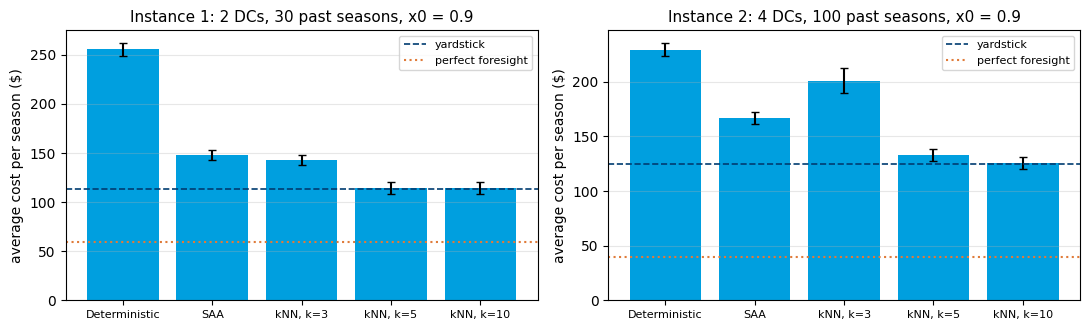

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, inst, res in zip(axes, (INSTANCE_1, INSTANCE_2), (result_1, result_2)):
    names = list(APPROACHES)
    ax.bar(names, res.loc[names, "simulated cost"], yerr=res.loc[names, "±"], color="#009FDF", capsize=3)
    ax.axhline(res.loc["yardstick: true distribution", "simulated cost"], color="#003C71", ls="--", lw=1.2, label="yardstick")
    ax.axhline(res.loc["perfect foresight", "simulated cost"], color="#E07B39", ls=":", lw=1.5, label="perfect foresight")
    ax.set_title(f"{inst['name']}, x0 = {X0}", fontsize=11); ax.set_ylabel("average cost per season ($)")
    ax.tick_params(axis="x", labelsize=8); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Reading Instance 2.**

* **kNN with k = 10 is within about 1% of the yardstick.** It places about 70 at A and 60 at B, because
  at $x = 0.9$ an A-surge is likely but a B-surge is quite possible.
* **kNN with k = 3 does worse than SAA.** With four season types, three neighbours give a
  noisy, high variance distributional support.
* **SAA ignores the signal (input variable).** It spreads stock for an average season and pays about a third more than the
  best approach.
* **Deterministic plans for one average season.** The LP expects about \$10 and the plan pays about \$230.
* **P tells the same story.** kNN with k = 10 reaches about 0.32 of a possible 0.33 (the yardstick). kNN with
  k = 3 and Deterministic have P < 0: worse than SAA.


---
# Part 6: Simulations across multiple signals $x$

Today's signal is only one draw. Here we repeat the comparison at signals from −2 to 2: re-plan at each
signal, simulate 300 new seasons there, and average. The last table weights each signal by how often it
occurs ($x \sim N(0, 1)$).

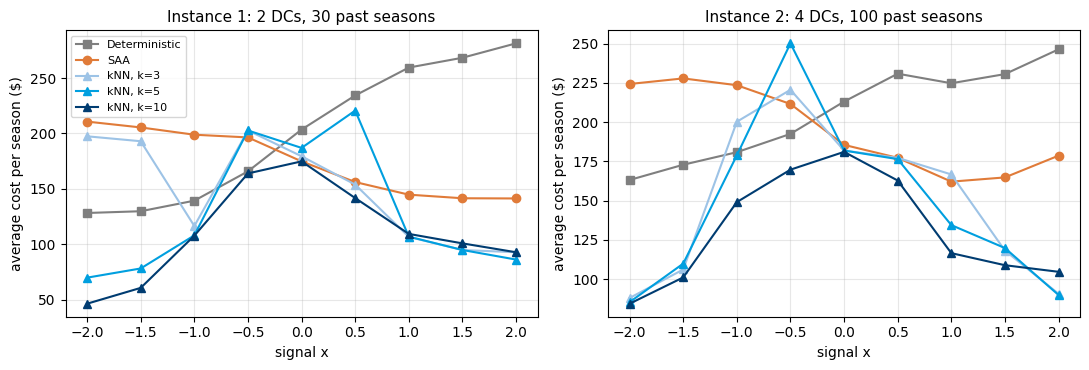

,Deterministic,SAA,"kNN, k=3","kNN, k=5","kNN, k=10"
"Instance 1: 2 DCs, 30 past seasons",200.7,174.5,155.6,156.8,132.2
"Instance 2: 4 DCs, 100 past seasons",208.1,192.9,174.1,172.9,148.9


In [14]:
def cost_across_signals(inst, signals, n_test=300, seed=2):
    rng = np.random.default_rng(seed)
    table = pd.DataFrame(index=signals, columns=list(APPROACHES), dtype=float)
    for x0 in signals:
        _, test = draw_seasons(inst, x0, n_test, rng)
        for name, (method, k) in APPROACHES.items():
            D, w, _ = scenarios(inst, method, x0, k)
            z = two_stage_lp(inst, D, w)["z"]
            table.loc[x0, name] = two_stage_lp(inst, test, np.full(n_test, 1 / n_test), z_fixed=z)["cost"]
    return table


SIGNALS = np.arange(-2, 2.01, 0.5)
across = {inst["name"]: cost_across_signals(inst, SIGNALS) for inst in (INSTANCE_1, INSTANCE_2)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
style = {"Deterministic": ("#7F7F7F", "s"), "SAA": ("#E07B39", "o"),
         "kNN, k=3": ("#9DC3E6", "^"), "kNN, k=5": ("#009FDF", "^"), "kNN, k=10": ("#003C71", "^")}
for ax, (title, table) in zip(axes, across.items()):
    for name in APPROACHES:
        ax.plot(SIGNALS, table[name], marker=style[name][1], color=style[name][0], label=name)
    ax.set_title(title, fontsize=11); ax.set_xlabel("signal x"); ax.set_ylabel("average cost per season ($)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

how_often = np.exp(-SIGNALS**2 / 2); how_often /= how_often.sum()     # weights from the N(0, 1) density
pd.DataFrame({title: table.T @ how_often for title, table in across.items()}).T.round(1)

**Takeaways.**

* **Deterministic and SAA ignore the signal.** Each fixed plan does well only where it happens to suit the
  likely season. SAA leans towards the DCs where a lost sale is the highest (A, and B in Instance 2).
* **kNN follows the signal.** It is cheaper wherever the signal is informative.
* **Averaged over how often each signal occurs, k = 10 is the cheapest in both instances.** The right $k$
  is a property of the decision, the data and the network. Choose it by simulating the **cost of the
  decision** (or by cross-validating it), and not by forecast accuracy.

---
# Part 7: Things to try

1. **Pick k.** Add `"kNN, k=20": ("knn", 20)` to `APPROACHES` and rerun Parts 4–6. Which k wins on
   Instance 2, with 100 past seasons? Why might the best $k$ grow with the amount of history?
2. **Another day.** Set `X0 = -0.9` or `X0 = 0` in Part 4. When does SAA catch up with kNN, and why?
3. **More history.** `add_history(INSTANCE_2, n=300, seed=5)`. What happens to kNN with $k = 3$?
4. **A bigger truck.** Set `INSTANCE_2["truck"] = 60`. Recourse becomes stronger: do the approaches move closer together? (Compare with VSS and EVPI on slide 33.)
5. **A fifth DC.** Add a DC E to Instance 2 (extend every list and matrix by one). No function changes.